# Solution: Analysing Weather data

In this notebook we analyse temperature records. We analyse a [snapshot](https://huggingface.co/datasets/haesleinhuepf/dwd_temperature_july2026) of the data that was saved right after the summer heatwave in Germany 2026.
The data originated from Deutscher Wetterdienst (DWD) Open Data portal. Source: https://opendata.dwd.de/, licensed CC-BY 4.0 Read more: https://www.dwd.de/EN/service/legal_notice/legal_notice_node.html

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import stackview
import os

If the data is not present yet, we download it.

In [2]:
if not os.path.exists("temp_recent.parquet"):
    from datasets import load_dataset
    
    ds = load_dataset("haesleinhuepf/dwd_temperature_july2026")
    
    # Save one split as Parquet
    ds["train"].to_parquet("temp_recent.parquet")

We connect to Blablador.

In [3]:
from bia_bob import config_blablador, bob

config_blablador()

The data looks like the following. The most important columns are:
* `TT_10` average temperature measured in a time-window of 10 minutes.
* `Stationsname` physical place (city) of the measurement
* `geoBreite` and `geoLaenge` latitude and longitude coordinate of the measurement station
* `MESS_DATUM` date and time of the measurement in format `YYYYMMDDhhmm`.

In [4]:
df = pd.read_parquet("temp_recent.parquet")
df.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor,Stations_id,von_datum,bis_datum,Stationshoehe,geoBreite,geoLaenge,Stationsname,Bundesland,Abgabe,datetime
0,44,202412310000,3,-999.0,6.4,6.0,87.3,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:00:00
1,44,202412310010,3,-999.0,6.4,6.1,86.9,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:10:00
2,44,202412310020,3,-999.0,6.4,5.9,87.5,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:20:00
3,44,202412310030,3,-999.0,6.4,6.0,87.1,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:30:00
4,44,202412310040,3,-999.0,6.4,5.9,87.9,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:40:00


In [5]:
df.columns

Index(['STATIONS_ID', 'MESS_DATUM', '  QN', 'PP_10', 'TT_10', 'TM5_10',
       'RF_10', 'TD_10', 'eor', 'Stations_id', 'von_datum', 'bis_datum',
       'Stationshoehe', 'geoBreite', 'geoLaenge', 'Stationsname', 'Bundesland',
       'Abgabe', 'datetime'],
      dtype='object')

## Places in the data
First we explore the dataset to see what regional data is available.

In [6]:
%%bob
Print out unique records in df["Stationsname"] where the name contains "Leipzig"

I will filter the `Stationsname` column of the DataFrame `df` for entries containing "Leipzig" and print the unique values.



In [7]:
leipzig_stations = df.loc[df["Stationsname"].str.contains("Leipzig", na=False), "Stationsname"].unique()
print(leipzig_stations)

['Leipzig-Holzhausen' 'Leipzig/Halle']


## Temperature highscores
Next, we identify the highest temperature measured in one place.

In [8]:
%%bob
Print out the maximum of column "TT_10" where "Stationsname" is "Leipzig/Halle"

I will filter `df` for rows where `Stationsname` equals `"Leipzig/Halle"` and print the maximum value of the `TT_10` column.



In [9]:
print(df.loc[df["Stationsname"] == "Leipzig/Halle", "TT_10"].max())

39.5


## Plotting
We can also plot the temperature records over time.

In [10]:
%%bob
Print out the maximum MESS_DATUM

I will print the maximum value of the `MESS_DATUM` column from `df`.



In [11]:
print(df["MESS_DATUM"].max())

202607032350


In [12]:
%%bob
Draw a plot of column "TT_10" for the date range from 202606010000 to 202606300000 (column "MESS_DATUM") at Stationsname "Leipzig/Halle"

I will filter `df` for station `"Leipzig/Halle"` and `MESS_DATUM` within the range 202606010000–202606300000, then plot `TT_10` against `MESS_DATUM`.



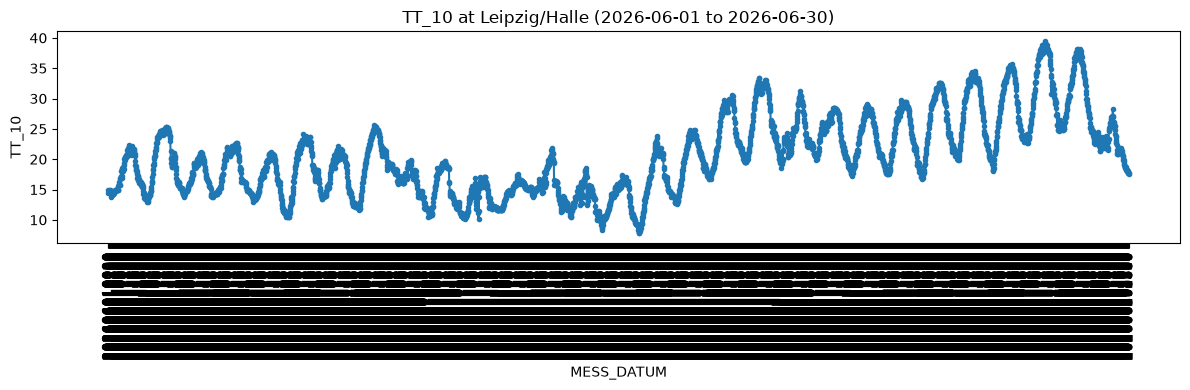

In [13]:
import matplotlib.pyplot as plt

sub = df[(df["Stationsname"] == "Leipzig/Halle") &
         (df["MESS_DATUM"].astype(int) >= 202606010000) &
         (df["MESS_DATUM"].astype(int) <= 202606300000)].copy()
sub = sub.sort_values("MESS_DATUM")

plt.figure(figsize=(12, 4))
plt.plot(sub["MESS_DATUM"].astype(str), sub["TT_10"], marker=".", linestyle="-")
plt.xticks(rotation=90)
plt.xlabel("MESS_DATUM")
plt.ylabel("TT_10")
plt.title("TT_10 at Leipzig/Halle (2026-06-01 to 2026-06-30)")
plt.tight_layout()
plt.show()

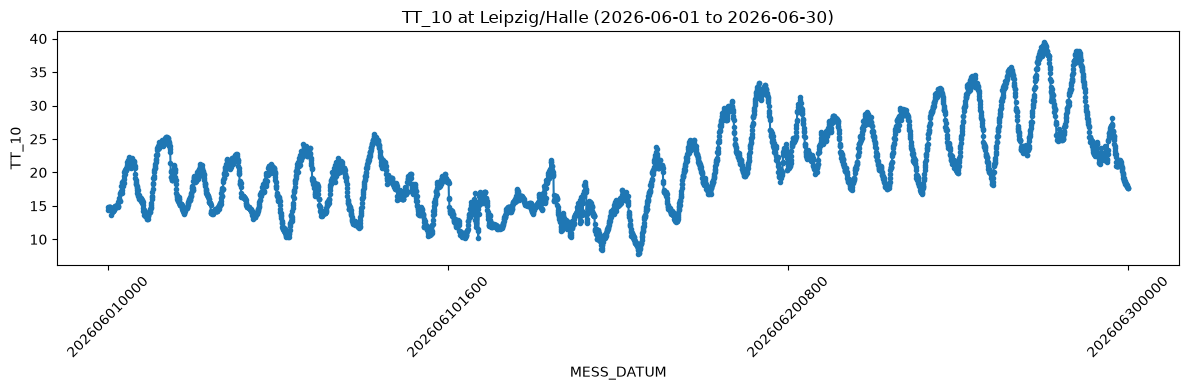

In [15]:
import matplotlib.pyplot as plt
import numpy as np

sub = df[(df["Stationsname"] == "Leipzig/Halle") &
         (df["MESS_DATUM"].astype(int) >= 202606010000) &
         (df["MESS_DATUM"].astype(int) <= 202606300000)].copy()
sub = sub.sort_values("MESS_DATUM")
sub = sub[sub["TT_10"] >= -900]

plt.figure(figsize=(12, 4))
plt.plot(sub["MESS_DATUM"].astype(str), sub["TT_10"], marker=".", linestyle="-")

ticks = np.linspace(0, len(sub) - 1, 4).astype(int)
plt.xticks(ticks, sub["MESS_DATUM"].astype(str).iloc[ticks], rotation=45)

plt.xlabel("MESS_DATUM")
plt.ylabel("TT_10")
plt.title("TT_10 at Leipzig/Halle (2026-06-01 to 2026-06-30)")
plt.tight_layout()
plt.show()

## Exercise
Determine where an when was the highest temperature measured in the dataset.

In [16]:
%%bob
Determine maximum TT_10 and give me corresponding MESS_DATUM and Stationsname

I will find the row with the maximum valid `TT_10` (excluding missing values below -900) and print the corresponding `MESS_DATUM` and `Stationsname`.



In [17]:
valid = df[df["TT_10"] >= -900]
row = valid.loc[valid["TT_10"].idxmax()]

print("TT_10:        ", row["TT_10"])
print("MESS_DATUM:   ", row["MESS_DATUM"])
print("Stationsname: ", row["Stationsname"])

TT_10:         41.4
MESS_DATUM:    202606271450
Stationsname:  Saarbrücken-Burbach
